# Chest X-ray Denoising: Classical Filter vs Deep Learning

**Problem.** A lower radiation dose protects patients but gives noisier X-rays. We want to recover the clean image while preserving anatomical detail.

**Question.** Do convolutional networks clearly beat a classical filter, and do skip connections help preserve fine details?



## 1. Setup

In [ ]:
from google.colab import drive
drive.mount('/content/drive')

import json, os, tarfile
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from PIL import Image
from scipy.ndimage import gaussian_filter
from sklearn.model_selection import GroupShuffleSplit
import tensorflow as tf
import keras
from keras import layers

print('GPU:', tf.config.list_physical_devices('GPU'))

BASE    = '/content/drive/MyDrive/autoencoder_project'
DATA    = f'{BASE}/data'        # images_001.tar.gz + Data_Entry_2017_v2020.csv
MODELS  = f'{BASE}/models'
RESULTS = f'{BASE}/results'
IMG_DIR = '/content/images'     # local disk, faster than Drive

SEED      = 42          # data split
IMG_SIZE  = 128
NOISE_STD = 0.1         # standard deviation of the Gaussian noise
EPOCHS    = 40
BATCH     = 32
RUN_SEEDS = [0, 1, 2]   # each network is trained 3 times

def mse(clean, pred):
    return np.mean((clean - pred) ** 2)

Mounted at /content/drive
GPU: [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')]


## 2. Data
NIH ChestX-ray14, first archive. We keep PA views only (more homogeneous) and split **by patient** (70/15/15), so that test chests are never seen during training. Images are grayscale, 128×128, in [0, 1].

In [ ]:
with tarfile.open(f'{DATA}/images_001.tar.gz') as tar:
    tar.extractall('/content', filter='data')

df = pd.read_csv(f'{DATA}/Data_Entry_2017_v2020.csv')
df = df[df['Image Index'].isin(os.listdir(IMG_DIR)) & (df['View Position'] == 'PA')]

def split_by_patient(d, test_size):
    gss = GroupShuffleSplit(n_splits=1, test_size=test_size, random_state=SEED)
    a, b = next(gss.split(d, groups=d['Patient ID']))
    return d.iloc[a], d.iloc[b]

train_df, rest_df = split_by_patient(df, 0.30)
val_df, test_df   = split_by_patient(rest_df, 0.50)

def load_images(d):
    imgs = [Image.open(f'{IMG_DIR}/{f}').convert('L').resize((IMG_SIZE, IMG_SIZE)) for f in d['Image Index']]
    return np.stack(imgs).astype(np.float32)[..., None] / 255.

x_train, x_val, x_test = load_images(train_df), load_images(val_df), load_images(test_df)
print(f'{len(df)} PA images, {df["Patient ID"].nunique()} patients')
print('train', x_train.shape, '| val', x_val.shape, '| test', x_test.shape)

3290 PA images, 1264 patients
train (2274, 128, 128, 1) | val (503, 128, 128, 1) | test (513, 128, 128, 1)


## 3. Noise
Additive Gaussian noise (σ = 0.1), clipped to [0, 1], as an approximation of low-dose noise.
- **Training:** the noise is added inside the networks by a Keras `GaussianNoise` layer, which is active only during training and draws new noise at every step.
- **Validation and test:** generated once with fixed seeds, so every method is judged on the same noisy images.

In [ ]:
def fixed_noise(x, seed):
    noise = np.random.default_rng(seed).normal(0, NOISE_STD, x.shape).astype(np.float32)
    return np.clip(x + noise, 0., 1.)

x_val_noisy, x_test_noisy = fixed_noise(x_val, seed=1), fixed_noise(x_test, seed=2)
print('MSE of the noisy test images:', mse(x_test, x_test_noisy))

MSE of the noisy test images: 0.009221591


## 4. Baseline: Gaussian filter
Each pixel becomes a Gaussian-weighted average of its neighbours: noise averages out, but edges blur too. Its only parameter, the width σ (pixels), is chosen on the validation set.

In [ ]:
def gaussian_denoise(x, sigma):
    return gaussian_filter(x, sigma=(0, sigma, sigma, 0))   # filter each image, not across images

val_mse = {s: mse(x_val, gaussian_denoise(x_val_noisy, s)) for s in [0.5, 0.75, 1.0, 1.25, 1.5, 2.0]}
best_sigma = min(val_mse, key=val_mse.get)
print({s: round(float(v), 6) for s, v in val_mse.items()}, '-> sigma =', best_sigma)

{0.5: 0.003945, 0.75: 0.001676, 1.0: 0.001309, 1.25: 0.001301, 1.5: 0.00144, 2.0: 0.001905} -> sigma = 1.25


## 5. Networks
Both networks come from the same function: identical layers, depth and filters. The `skip` flag is the only difference.
- **Encoder:** two 3×3 convolutions + max-pooling per level, 128 → 64 → 32 → 16.
- **Bottleneck:** 16×16×32 = 8,192 values, half the input (undercomplete).
- **Decoder:** 2×2 transposed convolutions back to 128×128; sigmoid output in [0, 1].
- **U-Net** (`skip=True`): encoder features are concatenated into the decoder at each level, so fine details can bypass the bottleneck.

In [ ]:
def conv_block(x, filters):
    x = layers.Conv2D(filters, 3, padding='same', activation='relu')(x)
    return layers.Conv2D(filters, 3, padding='same', activation='relu')(x)

def build_model(skip, name):
    inp = keras.Input((IMG_SIZE, IMG_SIZE, 1))
    x = layers.GaussianNoise(NOISE_STD)(inp)     # training only: new noise at every step
    x = layers.ReLU(max_value=1.0)(x)            # clip to [0, 1]

    saved = []
    for f in [32, 64, 128]:                      # encoder
        x = conv_block(x, f)
        saved.append(x)
        x = layers.MaxPooling2D()(x)

    x = layers.Conv2D(32, 1, activation='relu')(x)   # bottleneck

    for f, s in zip([128, 64, 32], reversed(saved)):  # decoder
        x = layers.Conv2DTranspose(f, 2, strides=2, padding='same')(x)
        if skip:
            x = layers.Concatenate()([x, s])     # skip connection
        x = conv_block(x, f)

    out = layers.Conv2D(1, 1, activation='sigmoid')(x)
    return keras.Model(inp, out, name=name)

NETWORKS = {'conv_autoencoder': False, 'unet': True}
for name, skip in NETWORKS.items():
    print(f'{name:17s} {build_model(skip, name).count_params():,} parameters')

conv_autoencoder  735,681 parameters
unet              929,217 parameters


## 6. Training
Same conditions for both networks: MSE loss, Adam (learning rate 1e-3), batch 32, 40 epochs. `ModelCheckpoint` saves the weights of the epoch with the lowest validation MSE. Each network is trained with **three seeds**, to check that the results do not depend on the initial weights.

In [ ]:
histories = {}
for name, skip in NETWORKS.items():
    for seed in RUN_SEEDS:
        keras.utils.set_random_seed(seed)
        model = build_model(skip, name)
        model.compile(optimizer=keras.optimizers.Adam(1e-3), loss='mse')
        keep_best = keras.callbacks.ModelCheckpoint(f'{MODELS}/{name}_seed{seed}.keras',
                                                    monitor='val_loss', save_best_only=True)
        h = model.fit(x_train, x_train,          # clean input: the noise layer corrupts it
                      validation_data=(x_val_noisy, x_val),
                      batch_size=BATCH, epochs=EPOCHS, callbacks=[keep_best], verbose=0)
        histories[f'{name}_seed{seed}'] = h.history['val_loss']
        print(f'{name:17s} seed {seed}: best epoch {np.argmin(h.history["val_loss"]) + 1:2d}, '
              f'best val MSE {min(h.history["val_loss"]):.6f}')

with open(f'{RESULTS}/histories.json', 'w') as f:
    json.dump(histories, f)

conv_autoencoder  seed 0: best epoch 40, best val MSE 0.000871
conv_autoencoder  seed 1: best epoch 38, best val MSE 0.000850
conv_autoencoder  seed 2: best epoch 39, best val MSE 0.000862
unet              seed 0: best epoch 38, best val MSE 0.000571
unet              seed 1: best epoch 40, best val MSE 0.000580
unet              seed 2: best epoch 39, best val MSE 0.000580


## 7. Learning curves

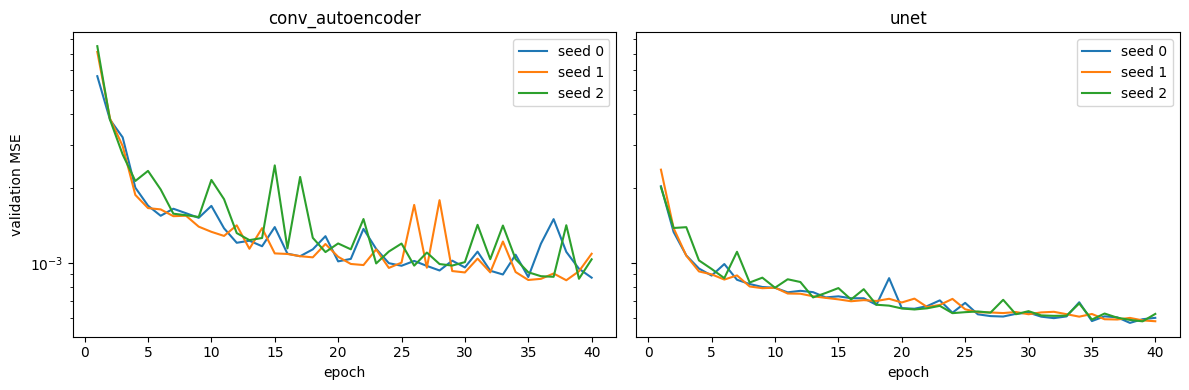

In [ ]:
fig, ax = plt.subplots(1, 2, figsize=(12, 4), sharey=True)
for a, name in zip(ax, NETWORKS):
    for seed in RUN_SEEDS:
        a.plot(range(1, EPOCHS + 1), histories[f'{name}_seed{seed}'], label=f'seed {seed}')
    a.set(title=name, xlabel='epoch', yscale='log')
    a.legend()
ax[0].set_ylabel('validation MSE')
plt.tight_layout(); plt.savefig(f'{RESULTS}/learning_curves.png', dpi=150); plt.show()

## 8. Test results
All methods on the same 513 noisy test images, never used for training or tuning. Networks: mean ± standard deviation over the three seeds.

In [ ]:
pred = {'Noisy input': x_test_noisy, 'Gaussian filter': gaussian_denoise(x_test_noisy, best_sigma)}
rows = [[m, mse(x_test, p), np.nan] for m, p in pred.items()]

for name in NETWORKS:
    errors = []
    for seed in RUN_SEEDS:
        model = keras.models.load_model(f'{MODELS}/{name}_seed{seed}.keras')
        p = model.predict(x_test_noisy, verbose=0)
        errors.append(mse(x_test, p))
        if seed == 0:
            pred[name] = p                       # seed 0 is used for the figures
    rows.append([name, np.mean(errors), np.std(errors)])

results = pd.DataFrame(rows, columns=['method', 'test MSE', 'std (3 seeds)'])
results.to_csv(f'{RESULTS}/test_results.csv', index=False)
results.round(6)

,method,test MSE,std (3 seeds)
0,Noisy input,0.009222,NaN
1,Gaussian filter,0.001287,NaN
2,conv_autoencoder,0.000875,0.000007
3,unet,0.000584,0.000005


## 9. Visual comparison
Three test images (networks: seed 0); the last row zooms on the ribs of the first one.

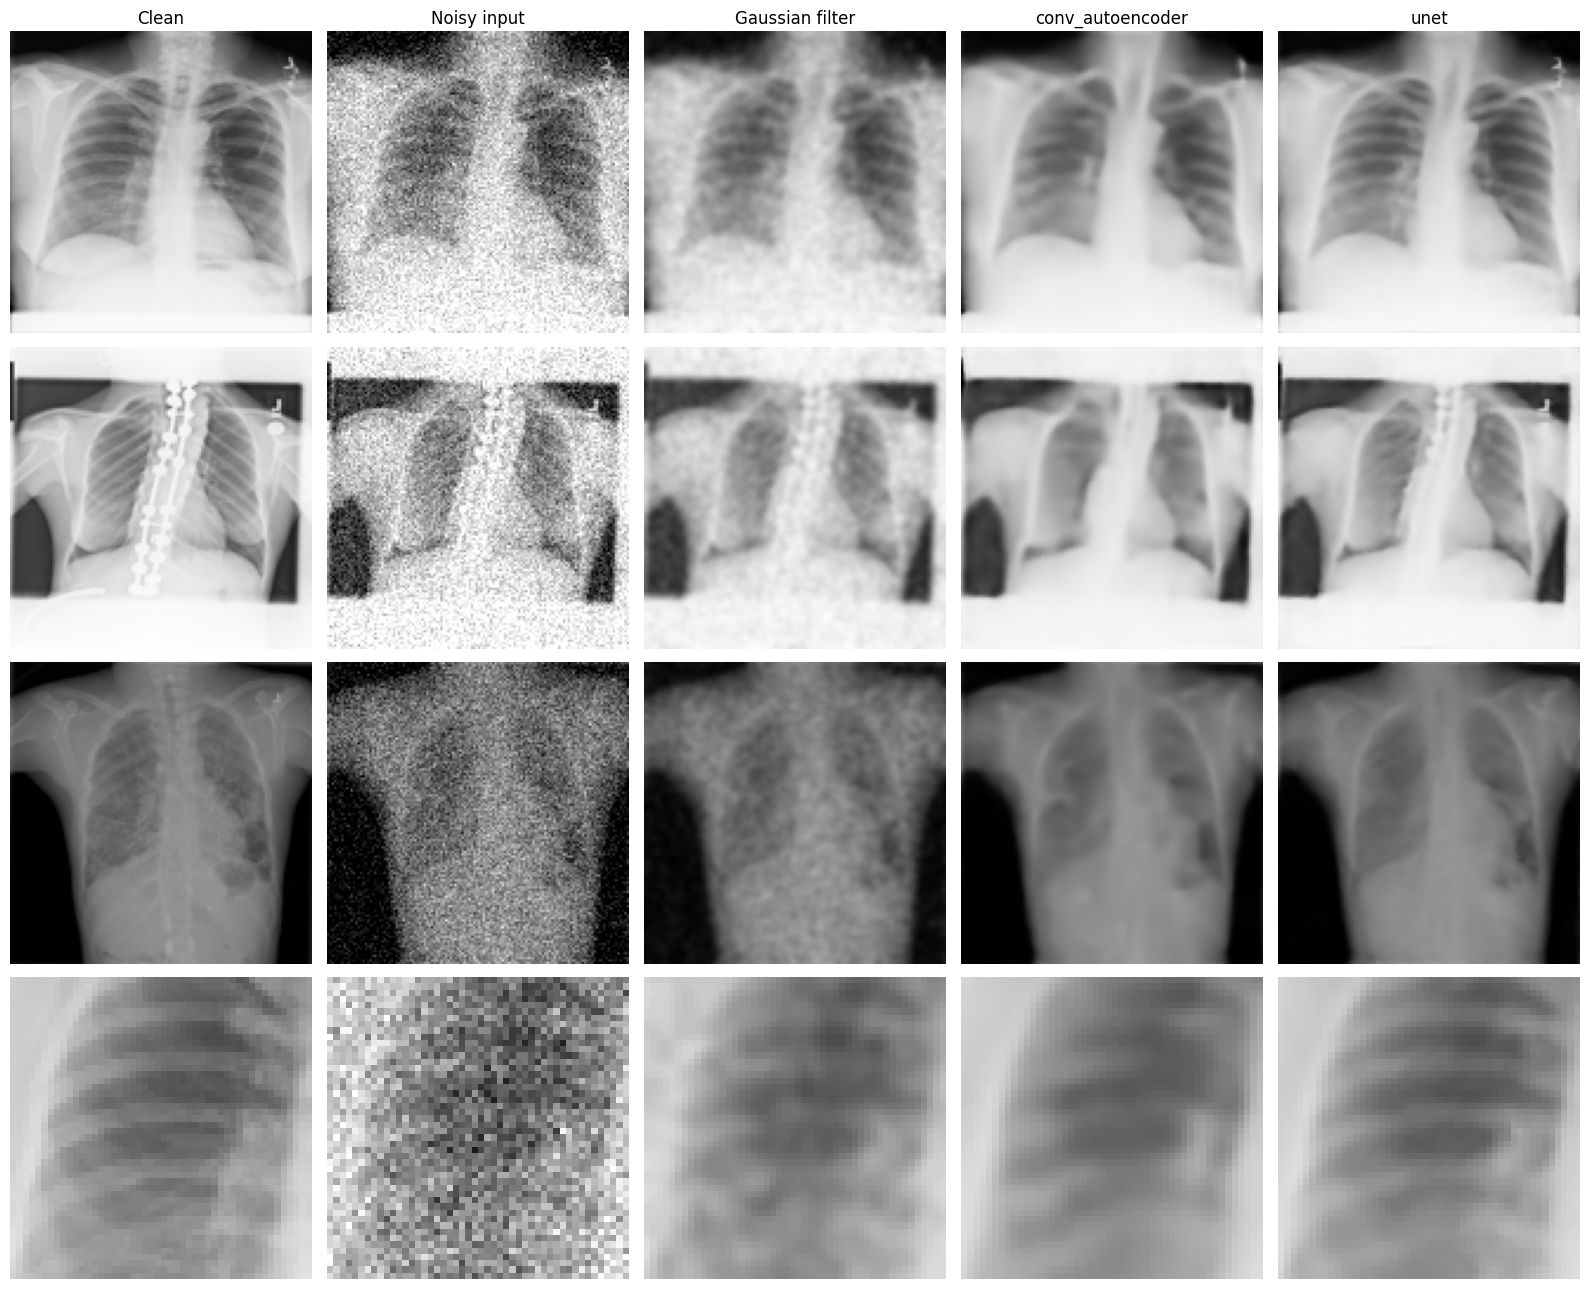

In [ ]:
panels = {'Clean': x_test, **pred}
fig, ax = plt.subplots(4, len(panels), figsize=(16, 13))
for c, (title, imgs) in enumerate(panels.items()):
    for r, i in enumerate([0, 100, 200]):
        ax[r, c].imshow(imgs[i, ..., 0], cmap='gray', vmin=0, vmax=1)
    ax[3, c].imshow(imgs[0, 32:80, 16:64, 0], cmap='gray', vmin=0, vmax=1)   # 48x48 zoom
    ax[0, c].set_title(title)
for a in ax.flat:
    a.axis('off')
plt.tight_layout(); plt.savefig(f'{RESULTS}/visual_comparison.png', dpi=150); plt.show()

## 10. Conclusions

**H1 – confirmed.** The U-Net test MSE is 0.000584 vs 0.001287 for the tuned Gaussian filter, about 2.2× lower (the autoencoder is 1.5× lower). The filter applies the same average everywhere, so it must trade noise against blur; the networks learn from the data where anatomical structures are.

**H2 – confirmed.** With identical layers, the U-Net beats the autoencoder (0.000584 vs 0.000875, −33%), a gap about 40 times larger than the spread between seeds. The figures show why: the autoencoder smooths away rib edges and the spinal implant, because all information must pass through the bottleneck; skip connections bring the spatially precise encoder features straight to the decoder. The U-Net also trains more stably (smoother validation curves).

**Limitations.** Synthetic Gaussian noise instead of real (Poisson) low-dose noise; 8-bit, 128×128 references; one archive, PA views only; the U-Net has 26% more parameters (929k vs 736k); best epochs were 38–40, so both networks might improve with longer training; a low MSE does not guarantee that small lesions are preserved.